# HotelPulse: Hotel Booking & Revenue Analytics

## Project Overview

This project analyzes hotel booking data to identify booking patterns,
revenue trends, customer behavior, and key business insights using
Python-based data analysis and visualization techniques.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
path="/content/hotel_bookings 2.csv"
df=pd.read_csv(path)

In [ ]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,1/7/2015
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,1/7/2015
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2/7/2015
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2/7/2015
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,3/7/2015


In [ ]:
df.shape

(119390, 32)

In [ ]:
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [ ]:
df.tail()



,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,6/9/2017
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,7/9/2017
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,7/9/2017
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,7/9/2017
119389,City Hotel,0,205,2017,August,35,29,2,7,2,...,No Deposit,9.0,NaN,0,Transient,151.20,0,2,Check-Out,7/9/2017


In [ ]:
df.isnull().sum()

,0
hotel,0
is_canceled,0
lead_time,0
arrival_date_year,0
arrival_date_month,0
arrival_date_week_number,0
arrival_date_day_of_month,0
stays_in_weekend_nights,0
stays_in_week_nights,0
adults,0


In [ ]:
df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
119385,False
119386,False
119387,False
119388,False


In [ ]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [ ]:
df.describe(include='object')

,hotel,arrival_date_month,meal,country,market_segment,distribution_channel,reserved_room_type,assigned_room_type,deposit_type,customer_type,reservation_status,reservation_status_date
count,119390,119390,119390,118902,119390,119390,119390,119390,119390,119390,119390,119390
unique,2,12,5,177,8,5,10,12,3,4,3,926
top,City Hotel,August,BB,PRT,Online TA,TA/TO,A,A,No Deposit,Transient,Check-Out,21/10/2015
freq,79330,13877,92310,48590,56477,97870,85994,74053,104641,89613,75166,1461


Cleaning the data

In [ ]:
missing = df.isnull().sum()
missing[missing > 0]

,0
children,4
country,488
agent,16340
company,112593


In [ ]:
missing_percentage=(df.isnull().sum()/len(df))*100
missing_percentage[missing_percentage > 0].sort_values(ascending=False)

,0
company,94.306893
agent,13.686238
country,0.408744
children,0.003350


In [ ]:
df_clean = df.copy()

In [ ]:
df_clean['children'] = df_clean['children'].fillna(0)

In [ ]:
df_clean['country'] = df_clean['country'].fillna('unknown')

In [ ]:
df_clean['agent'] = df_clean['agent'].fillna(0)

In [ ]:
df_clean = df_clean.drop(columns=['company'])

In [ ]:
df_clean.isnull().sum()

,0
hotel,0
is_canceled,0
lead_time,0
arrival_date_year,0
arrival_date_month,0
arrival_date_week_number,0
arrival_date_day_of_month,0
stays_in_weekend_nights,0
stays_in_week_nights,0
adults,0


duplicates


In [ ]:
df_clean = df_clean.drop_duplicates()

In [ ]:
df_clean.duplicated().sum()

np.int64(0)

In [ ]:
df_clean.shape

(87389, 31)

data transformation

In [ ]:
df_clean = df_clean.copy()

In [ ]:
df_clean['total_nights'] = (
    df_clean ['stays_in_weekend_nights'] +
  df_clean ['stays_in_week_nights']
    )

In [ ]:
df_clean[[ 'stays_in_weekend_nights', 'stays_in_week_nights', 'total_nights']].head()

,stays_in_weekend_nights,stays_in_week_nights,total_nights
0,0,0,0
1,0,0,0
2,0,1,1
3,0,1,1
4,0,2,2


Estimated revenue

In [ ]:
df_clean['estimated_revenue'] = df_clean['adr'] * df_clean['total_nights']

In [ ]:
df_clean[['adr', 'total_nights', 'estimated_revenue']].head()

,adr,total_nights,estimated_revenue
0,0.0,0,0.0
1,0.0,0,0.0
2,75.0,1,75.0
3,75.0,1,75.0
4,98.0,2,196.0


In [ ]:
df_clean['total_nights'].value_counts().sort_index().head()

,count
total_nights,
0,651
1,17177
2,15745
3,17839
4,13575


In [ ]:
df_clean[df_clean['total_nights']==0].shape

(651, 33)

In [ ]:
df_clean[df_clean['total_nights'] ==0]['is_canceled'].value_counts()

,count
is_canceled,
0,622
1,29


In [ ]:
df_clean[['total_nights', 'estimated_revenue']].head()

,total_nights,estimated_revenue
0,0,0.0
1,0,0.0
2,1,75.0
3,1,75.0
4,2,196.0


In [ ]:
df_clean[['total_nights' , 'estimated_revenue']].describe()

,total_nights,estimated_revenue
count,87389.000000,87389.000000
mean,3.630869,394.332860
std,2.763459,369.452677
min,0.000000,-63.800000
25%,2.000000,152.600000
50%,3.000000,299.000000
75%,5.000000,503.200000
max,69.000000,7590.000000


In [ ]:
df_clean[df_clean['estimated_revenue'] < 0][['adr', 'total_nights', 'estimated_revenue', 'hotel', 'is_canceled']]

,adr,total_nights,estimated_revenue,hotel,is_canceled
14969,-6.38,10,-63.8,Resort Hotel,0


outlier detection

In [ ]:
df_clean[df_clean['estimated_revenue'] < 0].shape

(1, 33)

In [ ]:
df_clean = df_clean[df_clean['adr'] >= 0].copy()

In [ ]:
df_clean[df_clean['estimated_revenue'] < 0].shape

(0, 33)

In [ ]:
df_clean.shape

(87388, 33)

In [ ]:

# Select completed hotel stays
completed_stays = df_clean[
    (df_clean['reservation_status'] == 'Check-Out') &
    (df_clean['total_nights'] > 0)
].copy()

# Estimate revenue from completed stays
completed_stays['estimated_completed_stay_revenue'] = (
    completed_stays['adr'] * completed_stays['total_nights']
)

# Display the results
print("Total cleaned bookings:", len(df_clean))
print("Completed stays:", len(completed_stays))

print("\nEstimated revenue by hotel:")
print(
    completed_stays.groupby('hotel')['estimated_completed_stay_revenue']
    .sum()
    .round(2)
)

Total cleaned bookings: 87388
Completed stays: 62741

Estimated revenue by hotel:
hotel
City Hotel      12159387.91
Resort Hotel    10816987.22
Name: estimated_completed_stay_revenue, dtype: float64


In [ ]:

# Compare completed-stay performance by hotel
hotel_performance = completed_stays.groupby('hotel').agg(
    completed_bookings=('hotel', 'size'),
    estimated_revenue=('estimated_completed_stay_revenue', 'sum'),
    average_adr=('adr', 'mean'),
    average_stay_nights=('total_nights', 'mean')
).round(2)

hotel_performance['revenue_share_percent'] = (
    hotel_performance['estimated_revenue']
    / hotel_performance['estimated_revenue'].sum()
    * 100
).round(2)

print(hotel_performance)

              completed_bookings  estimated_revenue  average_adr  \
hotel                                                              
City Hotel                 37106        12159387.91       109.07   
Resort Hotel               25635        10816987.22        94.25   

              average_stay_nights  revenue_share_percent  
hotel                                                     
City Hotel                   3.01                  52.92  
Resort Hotel                 4.26                  47.08  


In [ ]:

# Compare cancellation behaviour by hotel
cancellation_analysis = df_clean.groupby('hotel').agg(
    total_bookings=('is_canceled', 'count'),
    cancelled_bookings=('is_canceled', 'sum')
)

cancellation_analysis['cancellation_rate_percent'] = (
    cancellation_analysis['cancelled_bookings']
    / cancellation_analysis['total_bookings']
    * 100
).round(2)

print(cancellation_analysis)

              total_bookings  cancelled_bookings  cancellation_rate_percent
hotel                                                                      
City Hotel             53426               16049                      30.04
Resort Hotel           33962                7976                      23.49


In [ ]:

# Cancellation analysis by booking lead time

df_clean['lead_time_group'] = pd.cut(
    df_clean['lead_time'],
    bins=[-1, 7, 30, 90, 180, float('inf')],
    labels=[
        '0-7 days',
        '8-30 days',
        '31-90 days',
        '91-180 days',
        '181+ days'
    ]
)

lead_time_analysis = df_clean.groupby(
    'lead_time_group', observed=False
).agg(
    total_bookings=('is_canceled', 'count'),
    cancelled_bookings=('is_canceled', 'sum')
)

lead_time_analysis['cancellation_rate_percent'] = (
    lead_time_analysis['cancelled_bookings']
    / lead_time_analysis['total_bookings']
    * 100
).round(2)

print(lead_time_analysis)

                 total_bookings  cancelled_bookings  cancellation_rate_percent
lead_time_group                                                               
0-7 days                  18300                1543                       8.43
8-30 days                 16337                4145                      25.37
31-90 days                22744                7280                      32.01
91-180 days               18243                6382                      34.98
181+ days                 11764                4675                      39.74


In [ ]:

# Cancellation analysis by deposit type

deposit_analysis = df_clean.groupby('deposit_type').agg(
    total_bookings=('is_canceled', 'count'),
    cancelled_bookings=('is_canceled', 'sum')
)

deposit_analysis['cancellation_rate_percent'] = (
    deposit_analysis['cancelled_bookings']
    / deposit_analysis['total_bookings']
    * 100
).round(2)

print(deposit_analysis.sort_values(
    'cancellation_rate_percent', ascending=False
))

              total_bookings  cancelled_bookings  cancellation_rate_percent
deposit_type                                                               
Non Refund              1038                 983                      94.70
No Deposit             86243               23016                      26.69
Refundable               107                  26                      24.30


In [ ]:

# Validate deposit type and cancellation counts

deposit_validation = pd.crosstab(
    df_clean['deposit_type'],
    df_clean['is_canceled'],
    margins=True
)

deposit_validation.columns = [
    'Not Cancelled',
    'Cancelled',
    'Total'
]

print(deposit_validation)

              Not Cancelled  Cancelled  Total
deposit_type                                 
No Deposit            63227      23016  86243
Non Refund               55        983   1038
Refundable               81         26    107
All                   63363      24025  87388


In [ ]:

# Market Segment Analysis

market_analysis = df_clean.groupby('market_segment').agg(
    total_bookings=('market_segment', 'size'),
    cancelled_bookings=('is_canceled', 'sum'),
    average_adr=('adr', 'mean')
)

market_analysis['cancellation_rate_percent'] = (
    market_analysis['cancelled_bookings']
    / market_analysis['total_bookings'] * 100
).round(2)

market_analysis['average_adr'] = market_analysis['average_adr'].round(2)

print(market_analysis.sort_values('total_bookings', ascending=False))

                total_bookings  cancelled_bookings  average_adr  \
market_segment                                                    
Online TA                51615               18245       118.17   
Offline TA/TO            13889                2063        81.76   
Direct                   11804                1737       116.58   
Groups                    4941                1335        74.88   
Corporate                 4208                 510        68.18   
Complementary              702                  88         3.05   
Aviation                   227                  45       100.17   
Undefined                    2                   2        15.00   

                cancellation_rate_percent  
market_segment                             
Online TA                           35.35  
Offline TA/TO                       14.85  
Direct                              14.72  
Groups                              27.02  
Corporate                           12.12  
Complementary        

### Market Segment Analysis

The market segment analysis examined booking volume, average daily rate (ADR), and cancellation rates across different booking channels. Online Travel Agents (Online TA) contributed the highest number of bookings, with 51,615 bookings and a cancellation rate of 35.35%. Direct bookings recorded a lower cancellation rate of 14.72%, while Corporate bookings had the lowest cancellation rate among the main segments at 12.12%. Group bookings showed a cancellation rate of 27.02%.

These findings suggest that booking volume and cancellation behaviour differ across market segments. The hotel business could investigate cancellation patterns in online travel agent bookings and explore ways to encourage direct bookings. However, further analysis is required before concluding that a particular channel causes cancellations.


## Exploratory Data Analysis

### 1. Hotel-wise Booking Analysis

This analysis examines the number of bookings received by each hotel type.

In [ ]:
hotel_bookings= df_clean['hotel'].value_counts()
hotel_bookings

,count
hotel,
City Hotel,53426
Resort Hotel,33962


### Hotel-wise Booking Distribution

The following bar chart compares the number of bookings received by City Hotel and Resort Hotel.

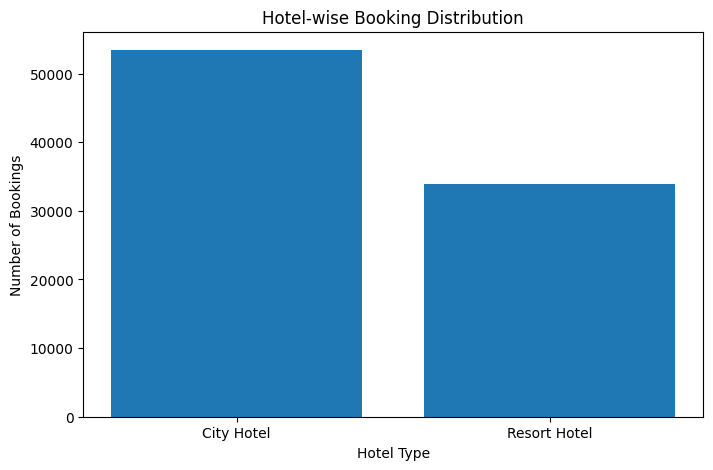

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(hotel_bookings.index, hotel_bookings.values)

plt.title('Hotel-wise Booking Distribution')
plt.xlabel('Hotel Type')
plt.ylabel('Number of Bookings')

plt.show()

### Revenue Analysis by Hotel

This analysis compares the estimated revenue generated by each hotel type.

In [ ]:
revenue_by_hotel = df_clean.groupby('hotel')['estimated_revenue'].sum().sort_values(ascending=False)

revenue_by_hotel

,estimated_revenue
hotel,
City Hotel,18773843.54
Resort Hotel,15686574.57


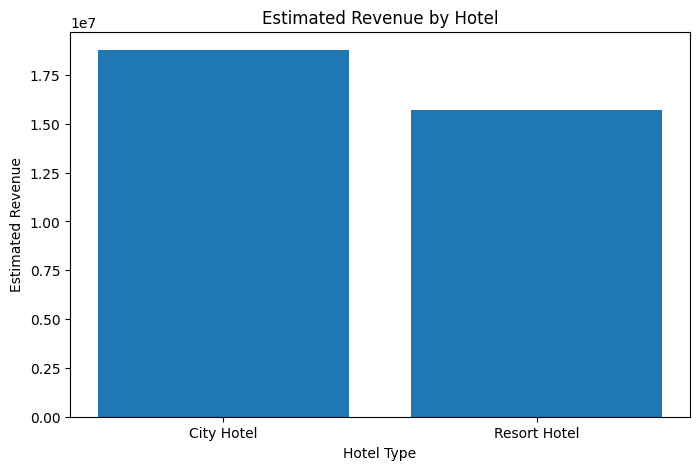

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(revenue_by_hotel.index, revenue_by_hotel.values)

plt.title('Estimated Revenue by Hotel')
plt.xlabel('Hotel Type')
plt.ylabel('Estimated Revenue')

plt.show()

### Country-wise Booking Analysis

This analysis identifies the countries contributing the highest number of hotel bookings.

In [ ]:
country_bookings = df_clean['country'].value_counts().head(10)

country_bookings

,count
country,
PRT,27449
GBR,10431
FRA,8837
ESP,7252
DEU,5387
ITA,3066
IRL,3016
BEL,2081
BRA,1995


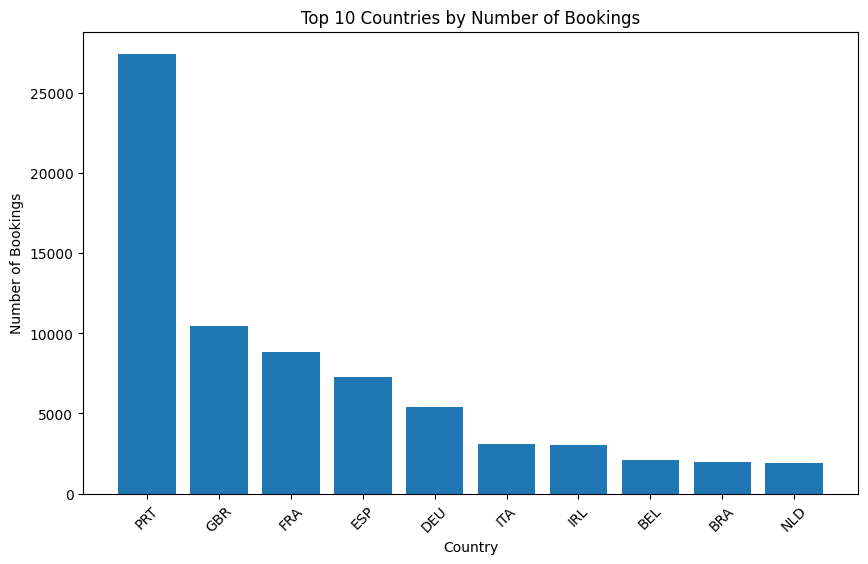

In [ ]:
plt.figure(figsize=(10, 6))

plt.bar(country_bookings.index, country_bookings.values)

plt.title('Top 10 Countries by Number of Bookings')
plt.xlabel('Country')
plt.ylabel('Number of Bookings')

plt.xticks(rotation=45)

plt.show()

### Monthly Booking Trend Analysis

This analysis examines booking patterns across different months to identify seasonal trends in hotel demand.

In [ ]:
monthly_bookings= df_clean['arrival_date_month'].value_counts()

monthly_bookings

,count
arrival_date_month,
August,11257
July,10056
May,8354
April,7908
June,7765
March,7512
October,6934
September,6689
February,6097


In [ ]:
month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_bookings = df_clean['arrival_date_month'].value_counts().reindex(month_order)

monthly_bookings

,count
arrival_date_month,
January,4693
February,6097
March,7512
April,7908
May,8354
June,7765
July,10056
August,11257
September,6689


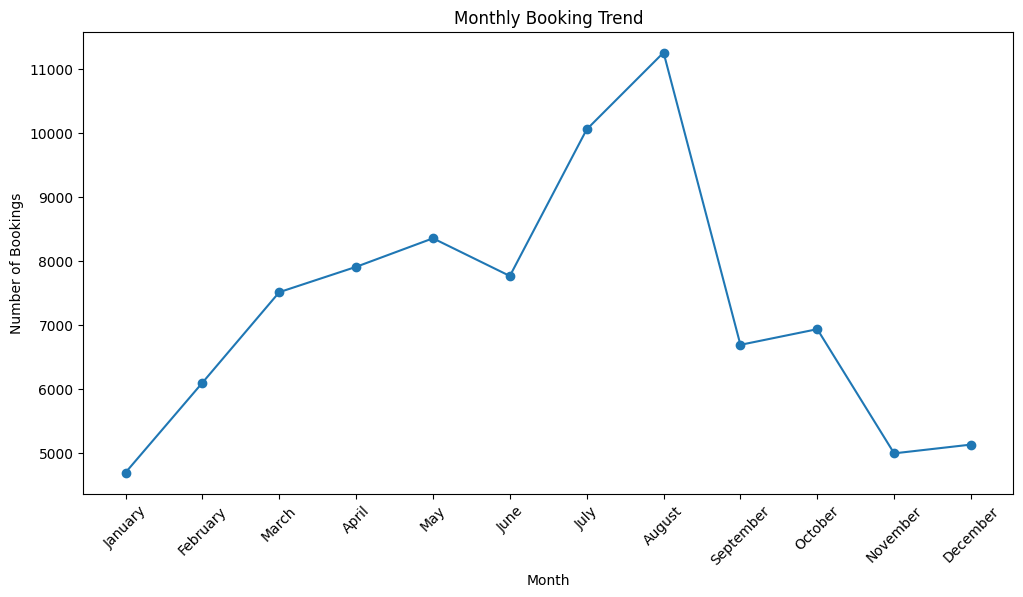

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(monthly_bookings.index, monthly_bookings.values, marker='o')

plt.title('Monthly Booking Trend')
plt.xlabel('Month')
plt.ylabel('Number of Bookings')

plt.xticks(rotation=45)

plt.show()

### Cancellation Analysis

This analysis examines the number of cancelled and non-cancelled hotel bookings to understand the cancellation pattern.

In [ ]:
cancellation_counts = df_clean['is_canceled'].value_counts().sort_index()

cancellation_counts

,count
is_canceled,
0,63363
1,24025


In [ ]:
cancellation_rate = (df_clean['is_canceled'].sum() / len(df_clean)) * 100

cancellation_rate

np.float64(27.49233304343846)

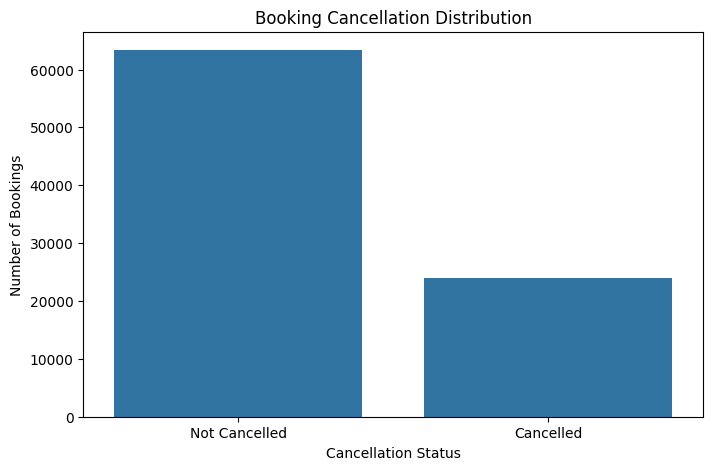

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df_clean, x='is_canceled')

plt.title('Booking Cancellation Distribution')
plt.xlabel('Cancellation Status')
plt.ylabel('Number of Bookings')

plt.xticks([0, 1], ['Not Cancelled', 'Cancelled'])

plt.show()

### Room Type Booking Analysis

This analysis examines the distribution of reserved room types to identify the room categories most frequently requested by customers.

In [ ]:
room_bookings = df_clean['reserved_room_type'].value_counts()

room_bookings

,count
reserved_room_type,
A,56545
D,17398
E,6048
F,2823
G,2052
B,999
C,915
H,596
L,6


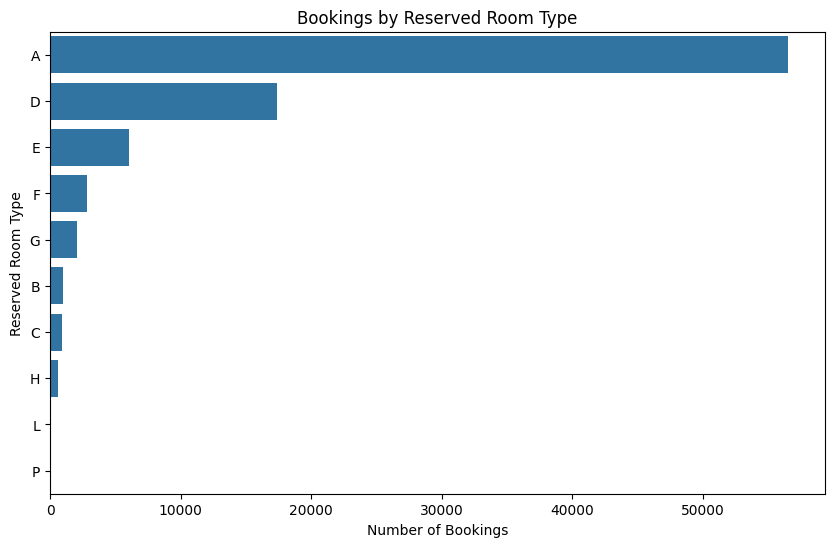

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=room_bookings.values,
    y=room_bookings.index
)

plt.title('Bookings by Reserved Room Type')
plt.xlabel('Number of Bookings')
plt.ylabel('Reserved Room Type')

plt.show()

### Customer Type Analysis

This analysis examines the distribution of bookings across different customer types to identify the most common customer segment.

In [ ]:
customer_bookings = df_clean['customer_type'].value_counts()

customer_bookings

,count
customer_type,
Transient,71982
Transient-Party,11723
Contract,3139
Group,544


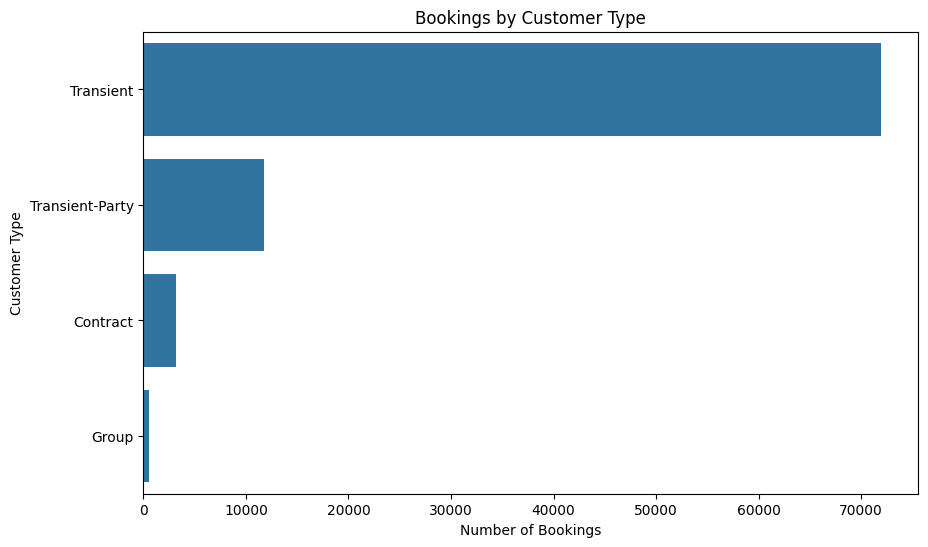

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=customer_bookings.values,
    y=customer_bookings.index
)

plt.title('Bookings by Customer Type')
plt.xlabel('Number of Bookings')
plt.ylabel('Customer Type')

plt.show()

### Average Order Value Analysis

Average Order Value (AOV) represents the average estimated revenue generated per booking. It is calculated by dividing the total estimated revenue by the total number of bookings.

In [ ]:
aov = df_clean['estimated_revenue'].mean()

aov

np.float64(394.3381025998994)

In [ ]:
print(f"Average Order Value: {aov:.2f}")

Average Order Value: 394.34


### Revenue Analysis by Customer Type

This analysis compares estimated revenue across different customer types to identify the customer segment generating the highest estimated revenue.

In [ ]:
revenue_by_customer = (
    df_clean.groupby('customer_type')['estimated_revenue']
    .sum()
    .sort_values(ascending=False)
)

revenue_by_customer

,estimated_revenue
customer_type,
Transient,29247850.27
Transient-Party,3434813.56
Contract,1641846.82
Group,135907.46


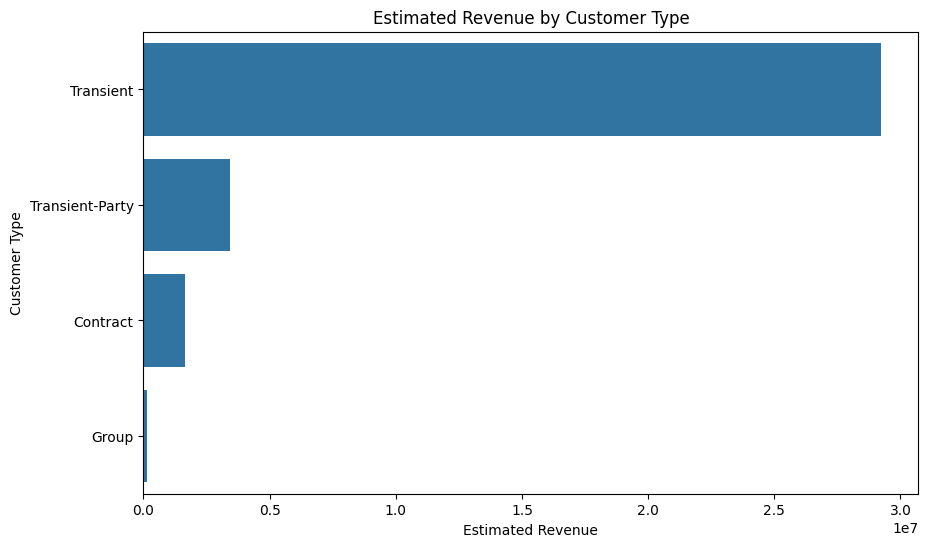

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=revenue_by_customer.values,
    y=revenue_by_customer.index
)

plt.title('Estimated Revenue by Customer Type')
plt.xlabel('Estimated Revenue')
plt.ylabel('Customer Type')

plt.show()

### Monthly Revenue Analysis

This analysis examines estimated revenue across different arrival months to identify seasonal revenue patterns.

In [ ]:
monthly_revenue = (
    df_clean.groupby('arrival_date_month')['estimated_revenue']
    .sum()
    .reindex(month_order)
)

monthly_revenue

,estimated_revenue
arrival_date_month,
January,1079597.52
February,1473565.20
March,2048749.13
April,2787157.05
May,3122908.22
June,3496345.05
July,5862835.99
August,7240652.99
September,2689078.19


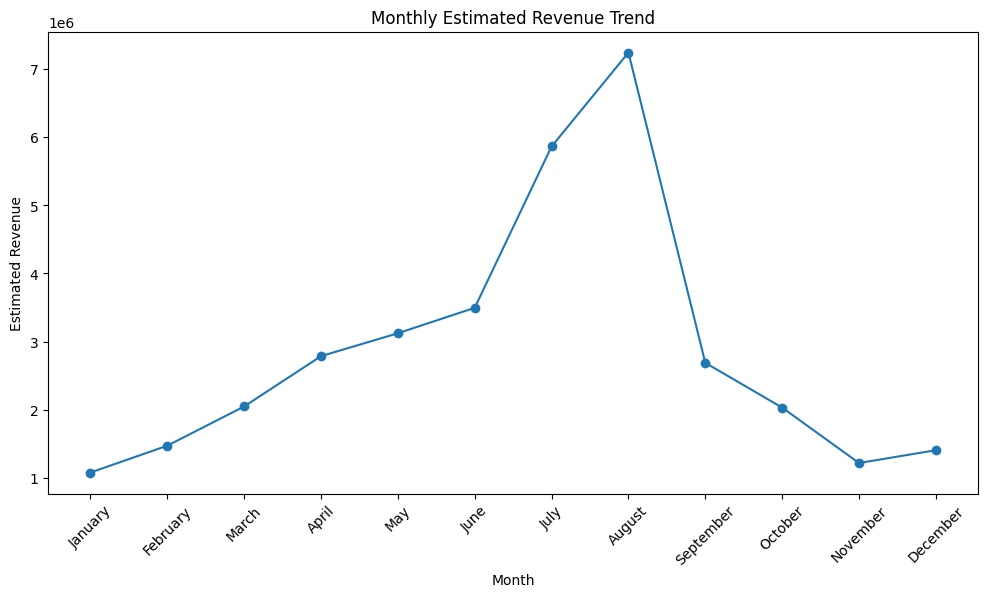

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_revenue.index,
    monthly_revenue.values,
    marker='o'
)

plt.title('Monthly Estimated Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Estimated Revenue')

plt.xticks(rotation=45)

plt.show()

### Meal Type Analysis

This analysis examines booking preferences across different meal types to identify the most frequently selected meal category.

In [ ]:
meal_bookings = df_clean['meal'].value_counts()

meal_bookings

,count
meal,
BB,67970
SC,9481
HB,9085
Undefined,492
FB,360


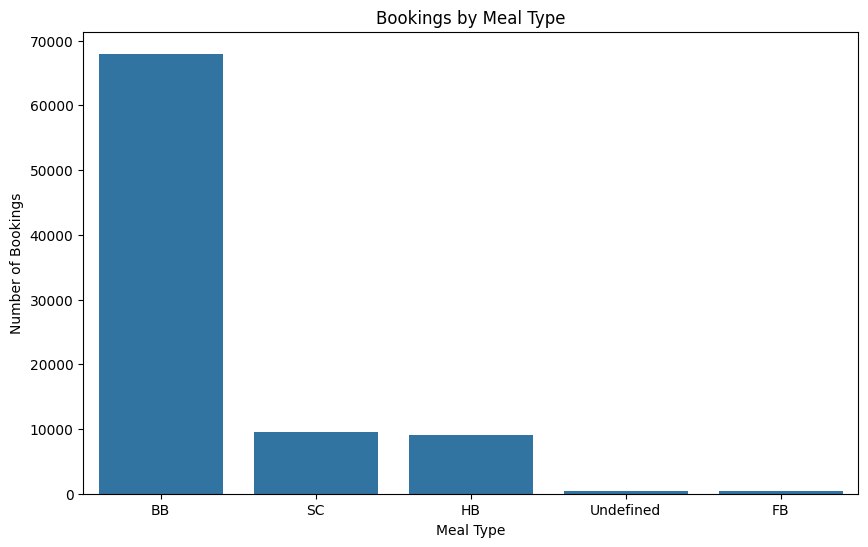

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=meal_bookings.index,
    y=meal_bookings.values
)

plt.title('Bookings by Meal Type')
plt.xlabel('Meal Type')
plt.ylabel('Number of Bookings')

plt.show()

### ADR Analysis

This analysis examines the Average Daily Rate (ADR) to understand hotel pricing patterns and identify unusually low or high room rates.

In [ ]:
df_clean['adr'].describe()

,adr
count,87388.00000
mean,106.34036
std,55.01209
min,0.00000
25%,72.00000
50%,98.10000
75%,134.00000
max,5400.00000


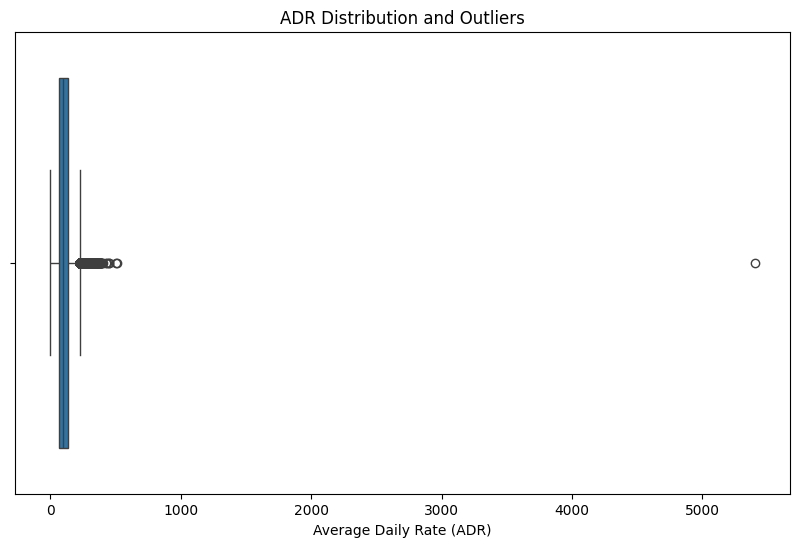

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(x=df_clean['adr'])

plt.title('ADR Distribution and Outliers')
plt.xlabel('Average Daily Rate (ADR)')

plt.show()

### Unusual Transaction Analysis

This analysis identifies unusually high ADR values that may represent potential outliers or exceptional transactions.

In [ ]:
df_clean[['hotel', 'adr', 'total_nights', 'estimated_revenue', 'is_canceled']].sort_values(
    by='adr',
    ascending=False
).head(10)

,hotel,adr,total_nights,estimated_revenue,is_canceled
48515,City Hotel,5400.00,1,5400.00,1
111403,City Hotel,510.00,1,510.00,0
15083,Resort Hotel,508.00,1,508.00,0
103912,City Hotel,451.50,2,903.00,0
13142,Resort Hotel,450.00,14,6300.00,1
13391,Resort Hotel,437.00,6,2622.00,1
39155,Resort Hotel,426.25,8,3410.00,0
39568,Resort Hotel,402.00,5,2010.00,0
39118,Resort Hotel,397.38,8,3179.04,0
13323,Resort Hotel,392.00,10,3920.00,1


In [ ]:
df_clean.loc[48515]

,48515
hotel,City Hotel
is_canceled,1
lead_time,35
arrival_date_year,2016
arrival_date_month,March
arrival_date_week_number,13
arrival_date_day_of_month,25
stays_in_weekend_nights,0
stays_in_week_nights,1
adults,2


In [ ]:
df_clean[df_clean['adr'] == 0][
    ['hotel', 'adr', 'total_nights', 'estimated_revenue', 'is_canceled',
     'reservation_status', 'customer_type']
].head(10)

,hotel,adr,total_nights,estimated_revenue,is_canceled,reservation_status,customer_type
0,Resort Hotel,0.0,0,0.0,0,Check-Out,Transient
1,Resort Hotel,0.0,0,0.0,0,Check-Out,Transient
125,Resort Hotel,0.0,1,0.0,0,Check-Out,Transient
167,Resort Hotel,0.0,0,0.0,0,Check-Out,Transient
168,Resort Hotel,0.0,0,0.0,0,Check-Out,Transient
196,Resort Hotel,0.0,0,0.0,0,Check-Out,Transient
197,Resort Hotel,0.0,0,0.0,0,Check-Out,Transient
421,Resort Hotel,0.0,2,0.0,1,Canceled,Transient-Party
428,Resort Hotel,0.0,2,0.0,0,Check-Out,Transient-Party
459,Resort Hotel,0.0,0,0.0,0,Check-Out,Transient


### Correlation Analysis

This analysis examines relationships among important numerical variables in the hotel booking dataset using a correlation matrix.

In [ ]:
numeric_columns = [
    'is_canceled',
    'lead_time',
    'stays_in_weekend_nights',
    'stays_in_week_nights',
    'adults',
    'children',
    'babies',
    'adr',
    'total_nights',
    'estimated_revenue'
]

correlation_matrix = df_clean[numeric_columns].corr()

correlation_matrix

,is_canceled,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,adr,total_nights,estimated_revenue
is_canceled,1.000000,0.184784,0.060182,0.082899,0.081777,0.067353,-0.020548,0.127963,0.084078,0.139446
lead_time,0.184784,1.000000,0.235078,0.310070,0.140438,0.028635,-0.003619,0.023565,0.318206,0.247599
stays_in_weekend_nights,0.060182,0.235078,1.000000,0.555524,0.088229,0.028557,0.013667,0.038997,0.786244,0.583333
stays_in_week_nights,0.082899,0.310070,0.555524,1.000000,0.095517,0.030464,0.016004,0.053326,0.950575,0.704771
adults,0.081777,0.140438,0.088229,0.095517,1.000000,0.023691,0.016634,0.248950,0.103928,0.199828
children,0.067353,0.028635,0.028557,0.030464,0.023691,1.000000,0.017420,0.326303,0.033302,0.218984
babies,-0.020548,-0.003619,0.013667,0.016004,0.016634,0.017420,1.000000,0.023442,0.016997,0.030729
adr,0.127963,0.023565,0.038997,0.053326,0.248950,0.326303,0.023442,1.000000,0.054191,0.555323
total_nights,0.084078,0.318206,0.786244,0.950575,0.103928,0.033302,0.016997,0.054191,1.000000,0.741565
estimated_revenue,0.139446,0.247599,0.583333,0.704771,0.199828,0.218984,0.030729,0.555323,0.741565,1.000000


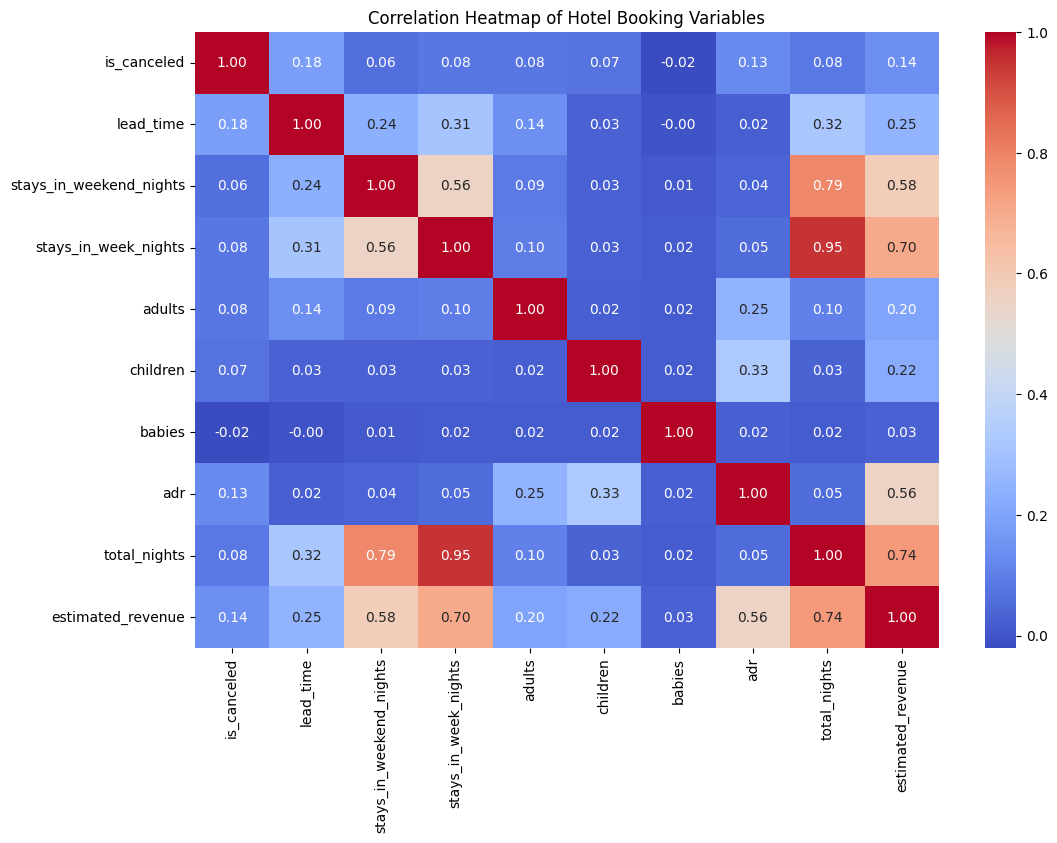

In [ ]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)

plt.title('Correlation Heatmap of Hotel Booking Variables')

plt.show()

### Year-wise Revenue Analysis

This analysis compares estimated revenue across different arrival years to identify changes in hotel revenue performance over time.

In [ ]:
yearly_revenue = (
    df_clean.groupby('arrival_date_year')['estimated_revenue']
    .sum()
    .sort_index()
)

yearly_revenue

,estimated_revenue
arrival_date_year,
2015,4885444.06
2016,15290849.01
2017,14284125.04


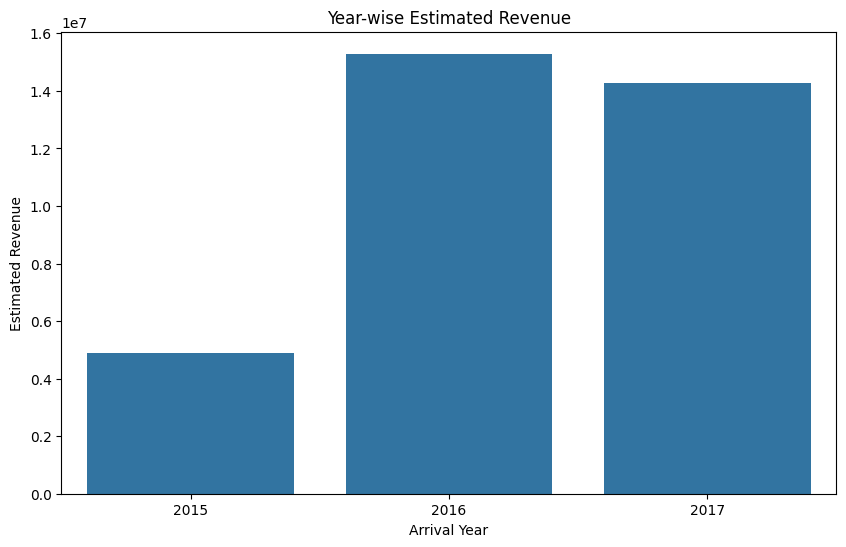

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=yearly_revenue.index.astype(str),
    y=yearly_revenue.values
)

plt.title('Year-wise Estimated Revenue')
plt.xlabel('Arrival Year')
plt.ylabel('Estimated Revenue')

plt.show()

### Year-wise Booking Count

This analysis compares the number of hotel bookings across different arrival years to understand changes in booking volume over time.

In [ ]:
yearly_bookings = (
    df_clean['arrival_date_year']
    .value_counts()
    .sort_index()
)

yearly_bookings

,count
arrival_date_year,
2015,13311
2016,42388
2017,31689


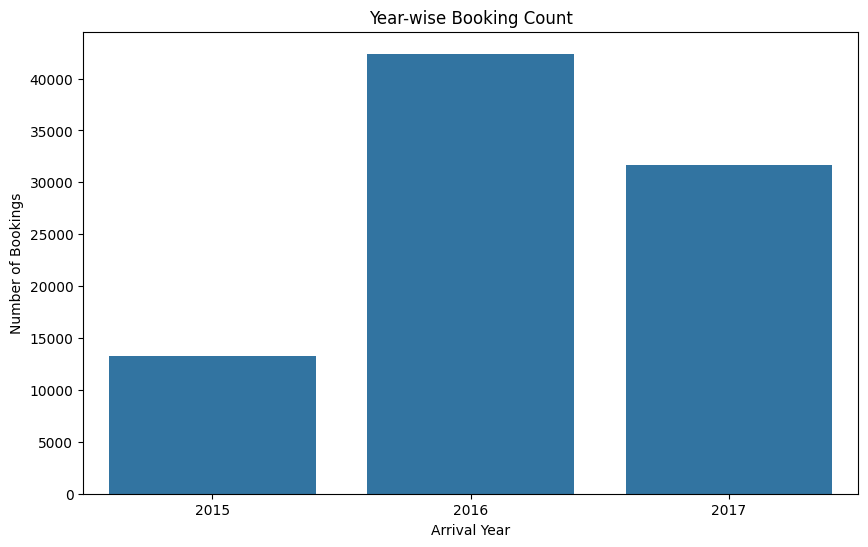

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=yearly_bookings.index.astype(str),
    y=yearly_bookings.values
)

plt.title('Year-wise Booking Count')
plt.xlabel('Arrival Year')
plt.ylabel('Number of Bookings')

plt.show()

### Monthly Booking Trend by Year

This analysis compares monthly booking volumes across different years to identify seasonal patterns and periods of increasing or declining demand.

In [ ]:
monthly_yearly_bookings = (
    df_clean.groupby(['arrival_date_year', 'arrival_date_month'])
    .size()
    .unstack()
    .reindex(columns=month_order)
)

monthly_yearly_bookings

arrival_date_month,January,February,March,April,May,June,July,August,September,October,November,December
arrival_date_year,,,,,,,,,,,,
2015,NaN,NaN,NaN,NaN,NaN,NaN,1674.0,2453.0,2839.0,2700.0,1663.0,1982.0
2016,1849.0,2806.0,3831.0,3770.0,3780.0,3517.0,3850.0,4423.0,3850.0,4234.0,3330.0,3148.0
2017,2844.0,3291.0,3681.0,4138.0,4574.0,4248.0,4532.0,4381.0,NaN,NaN,NaN,NaN


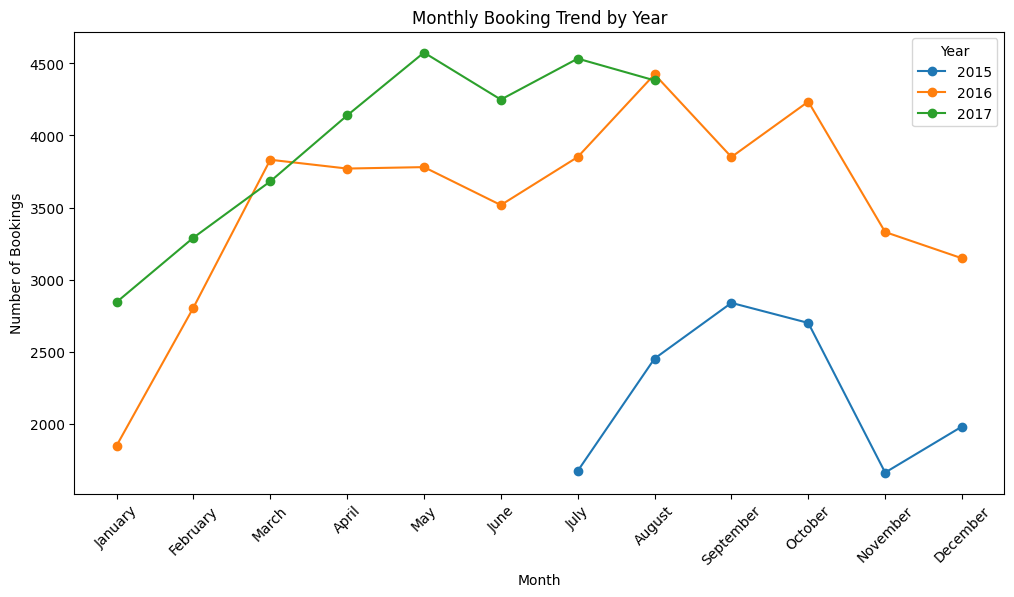

In [ ]:
plt.figure(figsize=(12, 6))

for year in monthly_yearly_bookings.index:
    plt.plot(
        month_order,
        monthly_yearly_bookings.loc[year],
        marker='o',
        label=str(year)
    )

plt.title('Monthly Booking Trend by Year')
plt.xlabel('Month')
plt.ylabel('Number of Bookings')

plt.xticks(rotation=45)
plt.legend(title='Year')

plt.show()

### Cancellation Rate by Hotel

This analysis compares the cancellation rate between City Hotel and Resort Hotel to identify differences in booking reliability and cancellation behavior.

In [ ]:
cancellation_by_hotel = (
    df_clean.groupby('hotel')['is_canceled']
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

cancellation_by_hotel

,is_canceled
hotel,
City Hotel,30.039681
Resort Hotel,23.485072


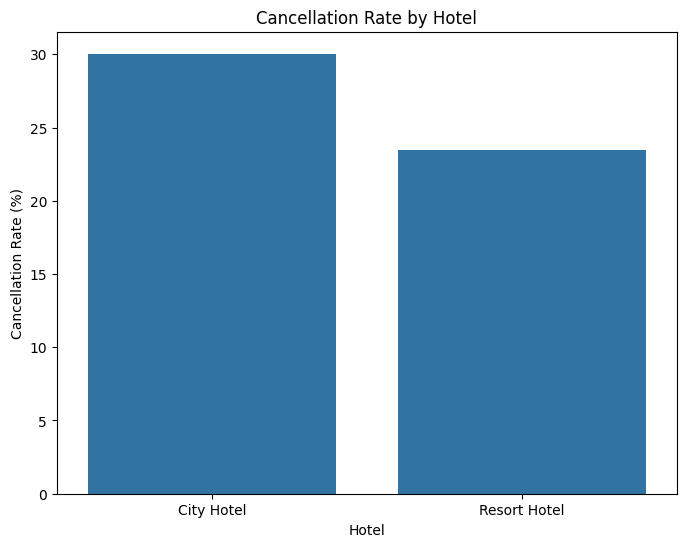

In [ ]:
plt.figure(figsize=(8, 6))

sns.barplot(
    x=cancellation_by_hotel.index,
    y=cancellation_by_hotel.values
)

plt.title('Cancellation Rate by Hotel')
plt.xlabel('Hotel')
plt.ylabel('Cancellation Rate (%)')

plt.show()

### Market Segment Analysis

This analysis examines the distribution of hotel bookings across different market segments to identify the major sources of customer demand.

In [ ]:
market_segment_bookings = (
    df_clean['market_segment']
    .value_counts()
)

market_segment_bookings

,count
market_segment,
Online TA,51615
Offline TA/TO,13889
Direct,11804
Groups,4941
Corporate,4208
Complementary,702
Aviation,227
Undefined,2


### Market Segment Booking Distribution

This visualization shows the distribution of hotel bookings across different market segments and highlights the major sources of customer bookings.

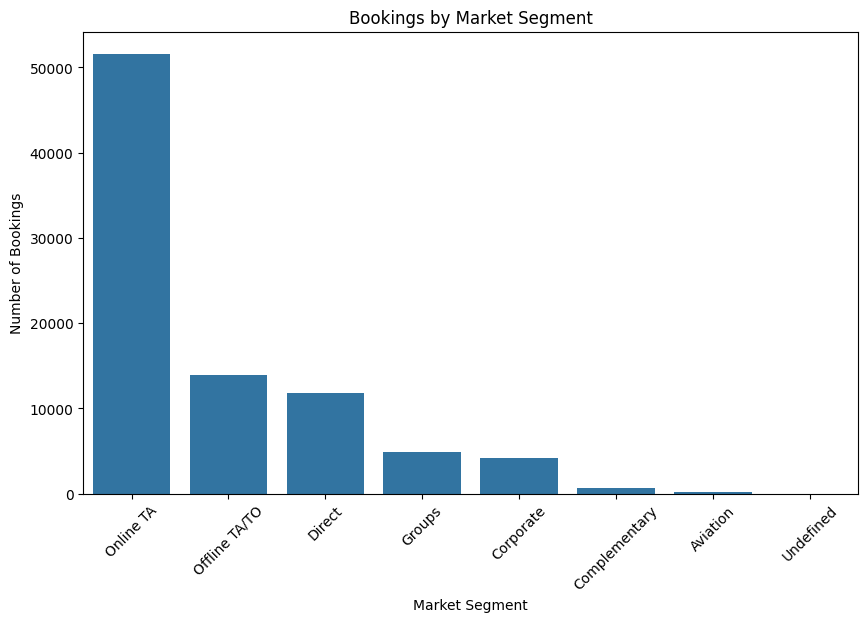

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=market_segment_bookings.index,
    y=market_segment_bookings.values
)

plt.title('Bookings by Market Segment')
plt.xlabel('Market Segment')
plt.ylabel('Number of Bookings')

plt.xticks(rotation=45)
plt.show()

### Cancellation Rate by Market Segment

This analysis compares cancellation rates across different market segments to identify segments with higher booking cancellation risk.

In [ ]:
cancellation_by_segment = (
    df_clean.groupby('market_segment')['is_canceled']
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

cancellation_by_segment

,is_canceled
market_segment,
Undefined,100.000000
Online TA,35.348251
Groups,27.018822
Aviation,19.823789
Offline TA/TO,14.853481
Direct,14.715351
Complementary,12.535613
Corporate,12.119772


### Cancellation Rate by Market Segment

This visualization compares the percentage of cancelled bookings across market segments to identify segments with relatively higher cancellation risk.

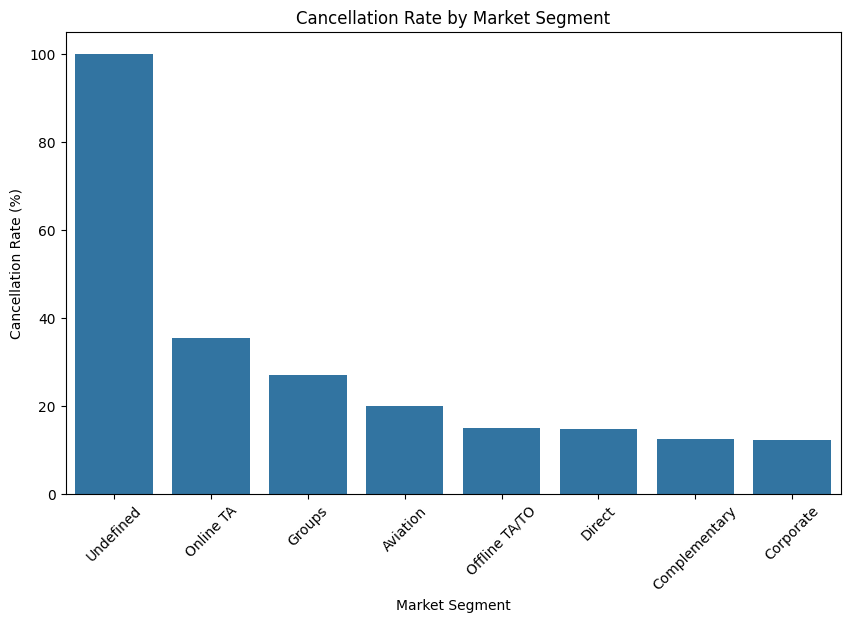

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=cancellation_by_segment.index,
    y=cancellation_by_segment.values
)

plt.title('Cancellation Rate by Market Segment')
plt.xlabel('Market Segment')
plt.ylabel('Cancellation Rate (%)')

plt.xticks(rotation=45)
plt.show()

### Revenue by Market Segment

This analysis compares estimated revenue generated by different market segments to identify the segments contributing most to hotel revenue.

In [ ]:
revenue_by_segment = (
    df_clean.groupby('market_segment')['estimated_revenue']
    .sum()
    .sort_values(ascending=False)
)

revenue_by_segment

,estimated_revenue
market_segment,
Online TA,22266141.88
Offline TA/TO,5416727.59
Direct,4856818.92
Groups,1238547.76
Corporate,594026.08
Aviation,83033.36
Complementary,5074.52
Undefined,48.00


### Revenue Contribution by Market Segment

This visualization compares estimated revenue across market segments to identify the major contributors to hotel revenue.

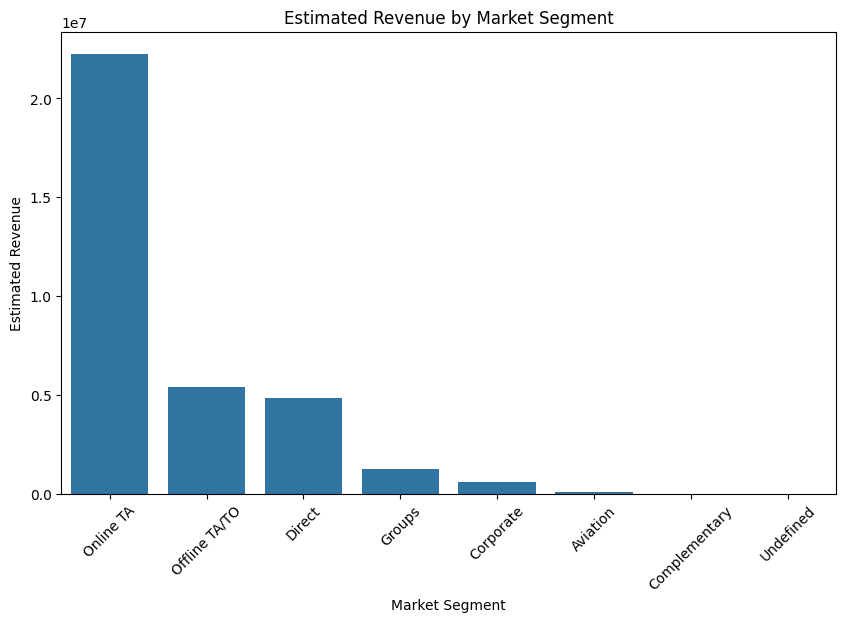

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=revenue_by_segment.index,
    y=revenue_by_segment.values
)

plt.title('Estimated Revenue by Market Segment')
plt.xlabel('Market Segment')
plt.ylabel('Estimated Revenue')

plt.xticks(rotation=45)
plt.show()

# Business Insights and Recommendations

## 1. Hotel Performance Analysis

The analysis shows that City Hotel contributed approximately 52.92% of the estimated room revenue from completed stays, while Resort Hotel contributed 47.08%. City Hotel recorded a higher average daily rate (ADR) of 109.07, compared with 94.25 for Resort Hotel. However, Resort Hotel guests stayed longer on average, at 4.26 nights compared with 3.01 nights at City Hotel.

**Recommendation:** City Hotel can investigate opportunities to improve guest retention and increase booking value. Resort Hotel can explore packages and services that encourage longer stays while monitoring revenue and operating costs.

## 2. Booking Cancellation Analysis

City Hotel recorded a cancellation rate of 30.04%, while Resort Hotel recorded 23.49%. This indicates that cancellation behaviour differs between the two hotel types.

**Recommendation:** Both hotels should examine their cancellation patterns and review booking policies, customer behaviour, and reservation conditions. City Hotel could investigate the factors associated with its higher cancellation rate before introducing changes.

## 3. Lead-Time Analysis

Bookings made further in advance showed higher cancellation rates in the analysed dataset. The cancellation rate increased from 8.43% for bookings made 0–7 days in advance to 39.74% for bookings made 181 or more days in advance.

**Recommendation:** Hotels could monitor reservations with longer lead times and use suitable reminder messages and booking confirmations to maintain customer engagement. These measures should be evaluated before concluding that they reduce cancellations.

## 4. Deposit-Type Analysis

Non-refundable bookings had the highest observed cancellation rate at 94.70%, compared with 26.69% for bookings with no deposit and 24.30% for refundable bookings. The refundable category contains only 107 bookings, while the non-refundable category contains 1,038 bookings.

**Recommendation:** Hotels should investigate the reasons behind the unusually high cancellation rate for non-refundable bookings and verify the relevant booking conditions and data. Deposit policies should not be changed based on this result alone, as the analysis identifies an association rather than a cause.

## 5. Market Segment Analysis

Online Travel Agents (Online TA) contributed the highest booking volume, with 51,615 bookings, and recorded a cancellation rate of 35.35%. Direct bookings had a cancellation rate of 14.72%, while Corporate bookings recorded 12.12%. Group bookings had a cancellation rate of 27.02%.

**Recommendation:** Hotels should investigate cancellation patterns across booking channels and customer segments. They can evaluate the customer experience and booking conditions for online travel agent reservations while exploring opportunities to strengthen direct bookings. Any strategy should be assessed using measurable booking and cancellation outcomes.

## Overall Conclusion

The HotelPulse project analysed hotel booking data to understand hotel performance, estimated room revenue from completed stays, length of stay, booking cancellations, lead time, deposit type, and market segments. The findings show differences in performance and cancellation behaviour across hotel types and booking categories.

These insights can help hotel management identify areas for further investigation and support data-informed decisions. However, the estimated room revenue is calculated using average daily rate multiplied by total nights and is not verified financial revenue or profit. The observed relationships do not establish causation, and further investigation is required before implementing business policy changes.
